# KLAR Split-Subset Error Subspace -> Held-out KLAR Recovery

This notebook tests the in-domain, non-overlapping version of the error-subspace hypothesis:

1. **Discovery subset:** learn FP16-minus-BNB-NF4 Layer-7 error directions from one set of KLAR facts.
2. **Held-out evaluation subset:** evaluate recovery on different KLAR facts that never participate in subspace discovery.
3. **Rank-1 causal test:** restore only the held-out sample's true error projection onto the first discovered direction.

The same record IDs and template IDs are used across languages, so semantic content is aligned across languages. Discovery and evaluation share the fixed five-shot demonstrations required by the task, but their evaluated subject--object facts are disjoint. This is an in-domain generalization test, not a same-sample oracle fit.


In [1]:
import gc, json, math, os, random, urllib.parse, urllib.request, warnings, zipfile
from collections import Counter, defaultdict
from pathlib import Path

os.environ.setdefault('HF_ENDPOINT', 'https://hf-mirror.com')
os.environ.setdefault('HF_HOME', '/root/autodl-tmp/huggingface')
os.environ.setdefault('HF_DATASETS_CACHE', '/root/autodl-tmp/huggingface/datasets')
os.environ.setdefault('HF_HUB_DISABLE_XET', '1')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

torch.set_grad_enabled(False)

# Faster matrix multiplication for the very large score GEMMs on Ampere+ GPUs.
if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = True
torch.set_float32_matmul_precision('high')

## 0. Configuration

The default uses 256 discovery facts and 20 held-out evaluation facts per language. Analysis covers ranks 1--128, while recovery is intentionally restricted to rank 1 for direct comparison with the earlier Tatoeba-to-KLAR experiment. GPU placement, KV cache, and batched conditions are enabled.


In [2]:
FP16_CHECKPOINT = Path('/root/autodl-tmp/models/llama3.1-8b/llama3.1-8b-instruct')
QUANT_MODEL_NAME = 'BNB-NF4'

LANGUAGES = ['ca', 'en', 'es', 'fr', 'hu', 'nl', 'tr', 'ar', 'el', 'he', 'ja', 'ko', 'zh']
TARGET_LANGUAGES = [language for language in LANGUAGES if language != 'en']
LANGUAGE_SCRIPT_GROUPS = {
    'ca': 'Latin', 'en': 'Latin', 'es': 'Latin', 'fr': 'Latin',
    'hu': 'Latin', 'nl': 'Latin', 'tr': 'Latin',
    'ar': 'Non-Latin', 'el': 'Non-Latin', 'he': 'Non-Latin',
    'ja': 'Non-Latin', 'ko': 'Non-Latin', 'zh': 'Non-Latin',
}
SCRIPT_GROUP_ORDER = ['Latin', 'Non-Latin']

SEED = 2026
DTYPE = torch.float16
DEVICE_MAP = 'auto'
FORCE_SINGLE_GPU_MODELS = False
USE_KV_CACHE = True
TRUST_REMOTE_CODE = True
MAX_LENGTH = 512
BATCH_SIZE = 8

RECOVERY_LAYER = 7
KLAR_N_SHOT = 5
DISCOVERY_SAMPLES_PER_LANGUAGE = 256
EVAL_SAMPLES_PER_LANGUAGE = 20
ANALYSIS_RANKS = [1, 2, 4, 8, 16, 32, 64, 128]
RECOVERY_RANKS = [1]
SUBSPACE_DIMS = ANALYSIS_RANKS
ENERGY_WEIGHT_ALPHA = 1.0
SVD_NITER = 4
PATCH_BETAS = [1.0, 1.5]
PATCH_CONDITIONS_PER_BATCH = 4
KLAR_BATCH_SIZE = 2
KLAR_MAX_LENGTH = 512
KLAR_GENERATION_MAX_NEW_TOKENS = 8
KLAR_ADD_GENERATION_PROMPT = True
RECOMPUTE_DISCOVERY_ERRORS = False
RECOMPUTE_KLAR_RECOVERY = True

BASE_ANALYSIS_DIR = Path(
    '/root/autodl-tmp/analysis/'
    'type1_bridge_neuron_stats_paper_tatoeba_1000_12targets_latin_nonlatin/'
    'content_masked_mean_tokens'
)
OUTPUT_DIR = BASE_ANALYSIS_DIR / 'klar_split_error_subspace_recovery'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
KLAR_DATA_DIR = Path('/root/autodl-tmp/data/klar')

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print('Output:', OUTPUT_DIR)
print('Discovery: KLAR discovery facts only')
print('Evaluation: disjoint held-out KLAR facts only')
print('Quantized model:', QUANT_MODEL_NAME)
print('Recovery layer:', RECOVERY_LAYER)


Output: /root/autodl-tmp/analysis/type1_bridge_neuron_stats_paper_tatoeba_1000_12targets_latin_nonlatin/content_masked_mean_tokens/klar_split_error_subspace_recovery
Discovery: KLAR discovery facts only
Evaluation: disjoint held-out KLAR facts only
Quantized model: BNB-NF4
Recovery layer: 7


## 1. Build fact-disjoint KLAR subsets

The split is created at the fact/record level, before prompt construction. All templates belonging to a held-out fact are excluded from discovery. The selected record and template IDs are shared across languages so cross-language comparisons are content aligned.


In [3]:
def load_klar_language(language):
    path = KLAR_DATA_DIR / f'{language}.json'
    if not path.is_file():
        raise FileNotFoundError(f'Missing KLAR language file: {path}')
    raw = json.loads(path.read_text(encoding='utf-8'))
    flattened = []
    for relation_index, relation in enumerate(raw):
        relation_name = relation.get('relation_name', f'relation_{relation_index}')
        relation_id = relation.get('relation_id', str(relation_index))
        templates = relation['prompt_templates']
        for sample in relation['samples']:
            variants = []
            for template_id, template in enumerate(templates):
                variants.append({
                    'question': template.replace(
                        '<subject>', sample['subject']
                    ).split('<mask>')[0],
                    'answer': sample['object'],
                    'template_id': template_id,
                    'relation_name': relation_name,
                    'relation_id': relation_id,
                    'fact_index': sample.get('index', len(flattened)),
                })
            flattened.append(variants)
    if len(flattened) <= KLAR_N_SHOT:
        raise ValueError(f'{language}: insufficient KLAR facts.')
    demonstrations = [flattened[index][index] for index in range(KLAR_N_SHOT)]
    return demonstrations, flattened[KLAR_N_SHOT:]


KLAR_RAW = {
    language: load_klar_language(language)
    for language in LANGUAGES
}

# Verify that record ordering and relations are aligned across languages.
english_evaluation = KLAR_RAW['en'][1]
for language in TARGET_LANGUAGES:
    evaluation = KLAR_RAW[language][1]
    if len(evaluation) != len(english_evaluation):
        raise RuntimeError(
            f'{language}: {len(evaluation)} records vs English '
            f'{len(english_evaluation)}.'
        )
    for record_id, (english_variants, target_variants) in enumerate(
        zip(english_evaluation, evaluation)
    ):
        if english_variants[0]['relation_id'] != target_variants[0]['relation_id']:
            raise RuntimeError(
                f'{language}: relation mismatch at record {record_id}.'
            )


def relation_stratified_ids(candidate_ids, n, seed):
    if len(candidate_ids) < n:
        raise ValueError(f'Only {len(candidate_ids)} candidates; requested {n}.')
    rng = random.Random(seed)
    grouped = defaultdict(list)
    for record_id in candidate_ids:
        relation = english_evaluation[record_id][0]['relation_id']
        grouped[relation].append(record_id)
    for values in grouped.values():
        rng.shuffle(values)
    relation_order = list(grouped)
    rng.shuffle(relation_order)
    selected = []
    round_index = 0
    while len(selected) < n:
        added = False
        for relation in relation_order:
            values = grouped[relation]
            if round_index < len(values):
                selected.append(values[round_index])
                added = True
                if len(selected) == n:
                    break
        if not added:
            break
        round_index += 1
    if len(selected) != n:
        raise RuntimeError(f'Could select only {len(selected)} of {n}.')
    return selected


all_record_ids = list(range(len(english_evaluation)))
EVAL_RECORD_IDS = relation_stratified_ids(
    all_record_ids, EVAL_SAMPLES_PER_LANGUAGE, SEED + 17
)
remaining_record_ids = [
    record_id for record_id in all_record_ids
    if record_id not in set(EVAL_RECORD_IDS)
]
DISCOVERY_RECORD_IDS = relation_stratified_ids(
    remaining_record_ids, DISCOVERY_SAMPLES_PER_LANGUAGE, SEED + 29
)
if set(DISCOVERY_RECORD_IDS) & set(EVAL_RECORD_IDS):
    raise RuntimeError('Discovery/evaluation fact leakage detected.')


def shared_template_id(record_id):
    minimum_templates = min(
        len(KLAR_RAW[language][1][record_id]) for language in LANGUAGES
    )
    if minimum_templates < 1:
        raise RuntimeError(f'Record {record_id} has no common template index.')
    return random.Random(SEED + 10_007 * record_id).randrange(minimum_templates)


split_rows = []
for split_name, record_ids in (
    ('discovery', DISCOVERY_RECORD_IDS),
    ('evaluation', EVAL_RECORD_IDS),
):
    for language in TARGET_LANGUAGES:
        evaluation = KLAR_RAW[language][1]
        for sample_index, record_id in enumerate(record_ids):
            template_id = shared_template_id(record_id)
            variant = evaluation[record_id][template_id]
            split_rows.append({
                'split': split_name,
                'language': language,
                'script_group': LANGUAGE_SCRIPT_GROUPS[language],
                'sample_id': f'{language}:{record_id}:{template_id}',
                'language_sample_index': sample_index,
                'record_id': record_id,
                'template_id': template_id,
                'relation_name': variant['relation_name'],
                'relation_id': variant['relation_id'],
                'fact_index': variant['fact_index'],
                'question': variant['question'],
                'answer': variant['answer'],
            })

KLAR_SPLIT_DF = pd.DataFrame(split_rows)
KLAR_SPLIT_DF.to_csv(OUTPUT_DIR / 'klar_fact_disjoint_split.csv', index=False)

discovery_pairs = set(zip(
    KLAR_SPLIT_DF.loc[KLAR_SPLIT_DF.split == 'discovery', 'language'],
    KLAR_SPLIT_DF.loc[KLAR_SPLIT_DF.split == 'discovery', 'record_id'],
))
evaluation_pairs = set(zip(
    KLAR_SPLIT_DF.loc[KLAR_SPLIT_DF.split == 'evaluation', 'language'],
    KLAR_SPLIT_DF.loc[KLAR_SPLIT_DF.split == 'evaluation', 'record_id'],
))
if discovery_pairs & evaluation_pairs:
    raise RuntimeError('Language/fact overlap remains after split construction.')

display(KLAR_SPLIT_DF.groupby(
    ['split', 'script_group', 'language'], as_index=False
).agg(
    samples=('sample_id', 'size'),
    relations=('relation_id', 'nunique'),
))
print('Shared discovery record IDs:', len(DISCOVERY_RECORD_IDS))
print('Shared evaluation record IDs:', len(EVAL_RECORD_IDS))


,split,script_group,language,samples,relations
0,discovery,Latin,ca,256,15
1,discovery,Latin,es,256,15
2,discovery,Latin,fr,256,15
3,discovery,Latin,hu,256,15
4,discovery,Latin,nl,256,15
5,discovery,Latin,tr,256,15
6,discovery,Non-Latin,ar,256,15
7,discovery,Non-Latin,el,256,15
8,discovery,Non-Latin,he,256,15
9,discovery,Non-Latin,ja,256,15


Shared discovery record IDs: 256
Shared evaluation record IDs: 20


## 2. Model and hidden-state utilities

In [4]:
def decoder_layers(model):
    for path in ('model.layers', 'model.decoder.layers', 'transformer.h', 'gpt_neox.layers'):
        obj = model
        ok = True
        for part in path.split('.'):
            if not hasattr(obj, part):
                ok = False
                break
            obj = getattr(obj, part)
        if ok:
            return obj
    raise AttributeError('Decoder layers not found.')


def input_device(model):
    return model.get_input_embeddings().weight.device


def load_tokenizer():
    tokenizer = AutoTokenizer.from_pretrained(
        FP16_CHECKPOINT, trust_remote_code=TRUST_REMOTE_CODE
    )
    tokenizer.padding_side = 'right'
    if tokenizer.pad_token_id is None:
        tokenizer.pad_token = tokenizer.eos_token
    return tokenizer


def model_device_map(name):
    if torch.cuda.is_available() and torch.cuda.device_count() >= 2:
        # Keep both models fully on GPU and avoid auto CPU offload.
        return {'': 1 if name == 'FP16' else 0}
    if torch.cuda.is_available() and FORCE_SINGLE_GPU_MODELS:
        # Enable only when one GPU has enough VRAM for FP16 + BNB-NF4.
        return {'': 0}
    return DEVICE_MAP


def load_model(name):
    if name == 'FP16':
        kwargs = {'torch_dtype': DTYPE}
    elif name == 'BNB-NF4':
        kwargs = {
            'quantization_config': BitsAndBytesConfig(
                load_in_4bit=True,
                bnb_4bit_quant_type='nf4',
                bnb_4bit_compute_dtype=DTYPE,
            )
        }
    else:
        raise KeyError(name)
    model = AutoModelForCausalLM.from_pretrained(
        FP16_CHECKPOINT,
        device_map=model_device_map(name),
        low_cpu_mem_usage=True,
        trust_remote_code=TRUST_REMOTE_CODE,
        **kwargs,
    ).eval()
    model.config.use_cache = USE_KV_CACHE
    placement = getattr(model, 'hf_device_map', None)
    print(f'{name} placement:', placement if placement is not None else input_device(model))
    return model


def release_models(*models):
    for model in models:
        if model is not None:
            del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def encode_batch(tokenizer, texts, device, max_length=MAX_LENGTH):
    batch = tokenizer(
        texts,
        return_tensors='pt',
        padding=True,
        truncation=True,
        max_length=max_length,
        add_special_tokens=True,
    )
    return {key: value.to(device) for key, value in batch.items()}


def content_token_mask(batch):
    mask = batch['attention_mask'].bool()
    input_ids = batch['input_ids']
    for special_id in TOKENIZER.all_special_ids:
        mask = mask & input_ids.ne(int(special_id))
    if (~mask.any(dim=1)).any():
        raise ValueError('At least one sequence has no content tokens.')
    return mask


def masked_mean_pool(sequence, token_mask):
    mask = token_mask[:, :sequence.shape[1]].to(
        device=sequence.device, dtype=sequence.dtype
    )
    denominator = mask.sum(dim=1, keepdim=True).clamp_min(1)
    return (sequence * mask.unsqueeze(-1)).sum(dim=1) / denominator


@torch.no_grad()
def collect_masked_mean_layer_output(model, texts, layer_index, batch_size=BATCH_SIZE):
    outputs = []
    layer = decoder_layers(model)[layer_index]
    for start in tqdm(
        range(0, len(texts), batch_size),
        desc=f'Layer {layer_index} pooled states', leave=False,
    ):
        batch = encode_batch(
            TOKENIZER, texts[start:start + batch_size], input_device(model)
        )
        captured = {}

        def hook(_module, _inputs, output):
            captured['hidden'] = output[0] if isinstance(output, tuple) else output

        handle = layer.register_forward_hook(hook)
        try:
            model(
                **batch, output_hidden_states=False,
                use_cache=False, return_dict=True,
            )
        finally:
            handle.remove()
        if 'hidden' not in captured:
            raise RuntimeError(f'Layer {layer_index} hook captured no output.')
        pooled = masked_mean_pool(
            captured['hidden'], content_token_mask(batch)
        )
        outputs.append(pooled.detach().float().cpu())
        del batch, captured, pooled
    return torch.cat(outputs, dim=0)


TOKENIZER = load_tokenizer()
print('Tokenizer loaded:', FP16_CHECKPOINT)


Tokenizer loaded: /root/autodl-tmp/models/llama3.1-8b/llama3.1-8b-instruct


## 3. Learn error subspaces on the KLAR discovery subset

For each discovery prompt, define the content-token masked-mean Layer-7 error

\[
e_{\lambda,s}=h^{FP}_{\lambda,s}-h^Q_{\lambda,s}.
\]

The evaluation facts are not accessed in this section. An uncentered randomized truncated SVD captures both mean drift and leading variation. Language, script-group, and global bases are learned only from discovery errors.


Loaded: /root/autodl-tmp/analysis/type1_bridge_neuron_stats_paper_tatoeba_1000_12targets_latin_nonlatin/content_masked_mean_tokens/klar_split_error_subspace_recovery/klar_discovery_bnb_nf4_layer7_256_errors.pt


,language,script_group,rank,explained_error_energy,mean_error_norm,rms_error_norm
0,ca,Latin,1,0.988148,0.379698,0.381990
1,ca,Latin,2,0.988937,0.379698,0.381990
2,ca,Latin,4,0.990252,0.379698,0.381990
3,ca,Latin,8,0.991919,0.379698,0.381990
4,ca,Latin,16,0.993899,0.379698,0.381990
...,...,...,...,...,...,...
91,zh,Non-Latin,8,0.992634,0.383307,0.385301
92,zh,Non-Latin,16,0.993910,0.383307,0.385301
93,zh,Non-Latin,32,0.995413,0.383307,0.385301
94,zh,Non-Latin,64,0.997097,0.383307,0.385301


,language,script_group,rank_at_50pct_energy,rank_at_70pct_energy,rank_at_80pct_energy,rank_at_90pct_energy
0,ca,Latin,1,1,1,1
1,es,Latin,1,1,1,1
2,fr,Latin,1,1,1,1
3,hu,Latin,1,1,1,1
4,nl,Latin,1,1,1,1
5,tr,Latin,1,1,1,1
6,ar,Non-Latin,1,1,1,1
7,el,Non-Latin,1,1,1,1
8,he,Non-Latin,1,1,1,1
9,ja,Non-Latin,1,1,1,1


,scope,name,rank,direction,energy_weight
1905,language,ca,128,1,1.000000
1906,language,ca,128,2,0.000798
1907,language,ca,128,3,0.000730
1908,language,ca,128,4,0.000601
1909,language,ca,128,5,0.000559
...,...,...,...,...,...
3820,common,Non-Latin,128,124,0.000026
3821,common,Non-Latin,128,125,0.000026
3822,common,Non-Latin,128,126,0.000026
3823,common,Non-Latin,128,127,0.000025


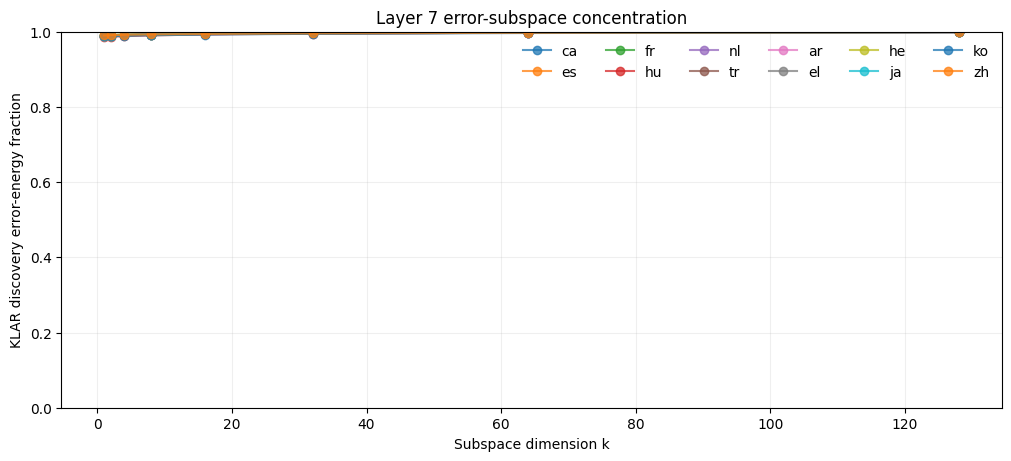

In [5]:
def klar_prompt_messages(language, record_id, template_id):
    demonstrations, evaluation = KLAR_RAW[language]
    messages = []
    for demonstration in demonstrations:
        messages.extend([
            {'role': 'user', 'content': demonstration['question']},
            {'role': 'assistant', 'content': demonstration['answer']},
        ])
    current = evaluation[int(record_id)][int(template_id)]
    messages.append({'role': 'user', 'content': current['question']})
    return messages


def klar_prompt_text(language, record_id, template_id):
    return TOKENIZER.apply_chat_template(
        klar_prompt_messages(language, record_id, template_id),
        tokenize=False,
        add_generation_prompt=KLAR_ADD_GENERATION_PROMPT,
    )


def rows_for_split(language, split_name):
    return KLAR_SPLIT_DF[
        (KLAR_SPLIT_DF.language == language)
        & (KLAR_SPLIT_DF.split == split_name)
    ].sort_values('language_sample_index').to_dict('records')


def prompts_for_split(language, split_name):
    return [
        klar_prompt_text(language, row['record_id'], row['template_id'])
        for row in rows_for_split(language, split_name)
    ]


KLAR_DISCOVERY_ERROR_CACHE = OUTPUT_DIR / (
    f'klar_discovery_{QUANT_MODEL_NAME.lower().replace("-", "_")}_'
    f'layer{RECOVERY_LAYER}_{DISCOVERY_SAMPLES_PER_LANGUAGE}_errors.pt'
)
discovery_sample_ids = KLAR_SPLIT_DF[
    KLAR_SPLIT_DF.split == 'discovery'
].sample_id.tolist()

if KLAR_DISCOVERY_ERROR_CACHE.exists() and not RECOMPUTE_DISCOVERY_ERRORS:
    error_payload = torch.load(KLAR_DISCOVERY_ERROR_CACHE, map_location='cpu')
    if error_payload['languages'] != TARGET_LANGUAGES:
        raise RuntimeError('Discovery error cache has a different language list.')
    if error_payload.get('sample_ids') != discovery_sample_ids:
        raise RuntimeError(
            'Discovery error cache belongs to a different KLAR split. '
            'Delete it or set RECOMPUTE_DISCOVERY_ERRORS=True.'
        )
    KLAR_DISCOVERY_ERRORS = error_payload['errors']
    print('Loaded:', KLAR_DISCOVERY_ERROR_CACHE)
else:
    q_model = load_model(QUANT_MODEL_NAME)
    quant_states = {
        language: collect_masked_mean_layer_output(
            q_model, prompts_for_split(language, 'discovery'), RECOVERY_LAYER
        )
        for language in TARGET_LANGUAGES
    }
    del q_model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    fp_model = load_model('FP16')
    fp_states = {
        language: collect_masked_mean_layer_output(
            fp_model, prompts_for_split(language, 'discovery'), RECOVERY_LAYER
        )
        for language in TARGET_LANGUAGES
    }
    del fp_model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    KLAR_DISCOVERY_ERRORS = {
        language: fp_states[language] - quant_states[language]
        for language in TARGET_LANGUAGES
    }
    torch.save({
        'errors': KLAR_DISCOVERY_ERRORS,
        'languages': TARGET_LANGUAGES,
        'layer': RECOVERY_LAYER,
        'samples_per_language': DISCOVERY_SAMPLES_PER_LANGUAGE,
        'sample_ids': discovery_sample_ids,
        'pooling': 'content-token masked mean',
        'definition': 'FP16 minus quantized',
    }, KLAR_DISCOVERY_ERROR_CACHE)
    del fp_states, quant_states
    print('Saved:', KLAR_DISCOVERY_ERROR_CACHE)


DISCOVERY_ERRORS = KLAR_DISCOVERY_ERRORS
MAX_SUBSPACE_DIM = max(SUBSPACE_DIMS)
SVD_DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
LANGUAGE_BASES_MAX = {}
LANGUAGE_SINGULAR_VALUES = {}
svd_rows = []
energy_threshold_rows = []

for language in TARGET_LANGUAGES:
    errors = KLAR_DISCOVERY_ERRORS[language].to(
        device=SVD_DEVICE, dtype=torch.float32
    )
    if MAX_SUBSPACE_DIM > min(errors.shape):
        raise ValueError(
            f'{language}: rank {MAX_SUBSPACE_DIM} exceeds '
            f'matrix limit {min(errors.shape)}.'
        )
    # Randomized truncated SVD is much faster than a full discovery-matrix SVD and
    # computes exactly the leading directions needed by this notebook.
    _, singular_values_gpu, right_vectors = torch.pca_lowrank(
        errors, q=MAX_SUBSPACE_DIM, center=False, niter=SVD_NITER
    )
    singular_values = singular_values_gpu.cpu()
    LANGUAGE_BASES_MAX[language] = right_vectors.cpu().contiguous()
    LANGUAGE_SINGULAR_VALUES[language] = singular_values
    total_energy = errors.square().sum().cpu().clamp_min(1e-12)
    cumulative_energy = singular_values.square().cumsum(0) / total_energy
    threshold_row = {
        'language': language,
        'script_group': LANGUAGE_SCRIPT_GROUPS[language],
    }
    for threshold in (0.50, 0.70, 0.80, 0.90):
        column = f'rank_at_{int(threshold * 100)}pct_energy'
        if float(cumulative_energy[-1]) < threshold:
            threshold_row[column] = f'>{MAX_SUBSPACE_DIM}'
        else:
            threshold_row[column] = int(
                torch.searchsorted(
                    cumulative_energy, torch.tensor(threshold)
                ).item() + 1
            )
    energy_threshold_rows.append(threshold_row)
    for rank in SUBSPACE_DIMS:
        svd_rows.append({
            'language': language,
            'script_group': LANGUAGE_SCRIPT_GROUPS[language],
            'rank': rank,
            'explained_error_energy': float(
                singular_values[:rank].square().sum() / total_energy
            ),
            'mean_error_norm': float(errors.mean(dim=0).norm()),
            'rms_error_norm': float(errors.square().sum(dim=1).mean().sqrt()),
        })
    del errors, singular_values_gpu, right_vectors


def common_basis(languages, rank):
    stacked = torch.cat([
        LANGUAGE_BASES_MAX[language][:, :rank]
        for language in languages
    ], dim=1) / math.sqrt(len(languages))
    basis, singular_values, _ = torch.linalg.svd(
        stacked.float(), full_matrices=False
    )
    return basis[:, :rank].contiguous(), singular_values


GLOBAL_BASES = {}
GROUP_BASES = {group: {} for group in SCRIPT_GROUP_ORDER}
COMMON_SPECTRA = {}
for rank in SUBSPACE_DIMS:
    GLOBAL_BASES[rank], COMMON_SPECTRA[('Global', rank)] = common_basis(
        TARGET_LANGUAGES, rank
    )
    for group in SCRIPT_GROUP_ORDER:
        group_languages = [
            language for language in TARGET_LANGUAGES
            if LANGUAGE_SCRIPT_GROUPS[language] == group
        ]
        GROUP_BASES[group][rank], COMMON_SPECTRA[(group, rank)] = common_basis(
            group_languages, rank
        )


def energy_weighted_common_basis(languages, rank):
    """Equal language mass, but weight each within-language PC by its energy."""
    weighted_components = []
    for language in languages:
        singular_values = LANGUAGE_SINGULAR_VALUES[language].float()
        total_energy = singular_values.square().sum().clamp_min(1e-12)
        explained_weights = (
            singular_values[:rank].square() / total_energy
        ).pow(ENERGY_WEIGHT_ALPHA)
        weighted_components.append(
            LANGUAGE_BASES_MAX[language][:, :rank]
            * explained_weights.sqrt().unsqueeze(0)
        )
    stacked = torch.cat(weighted_components, dim=1) / math.sqrt(len(languages))
    basis, singular_values, _ = torch.linalg.svd(
        stacked.float(), full_matrices=False
    )
    basis = basis[:, :rank].contiguous()
    direction_weights = (
        singular_values[:rank].square()
        / singular_values[0].square().clamp_min(1e-12)
    ).pow(ENERGY_WEIGHT_ALPHA)
    return basis, direction_weights.contiguous(), singular_values


LANGUAGE_ENERGY_WEIGHTS = {language: {} for language in TARGET_LANGUAGES}
WEIGHTED_GLOBAL_BASES = {}
WEIGHTED_GLOBAL_DIRECTION_WEIGHTS = {}
WEIGHTED_GROUP_BASES = {group: {} for group in SCRIPT_GROUP_ORDER}
WEIGHTED_GROUP_DIRECTION_WEIGHTS = {
    group: {} for group in SCRIPT_GROUP_ORDER
}
WEIGHTED_COMMON_SPECTRA = {}

for language in TARGET_LANGUAGES:
    singular_values = LANGUAGE_SINGULAR_VALUES[language].float()
    for rank in SUBSPACE_DIMS:
        LANGUAGE_ENERGY_WEIGHTS[language][rank] = (
            singular_values[:rank].square()
            / singular_values[0].square().clamp_min(1e-12)
        ).pow(ENERGY_WEIGHT_ALPHA).contiguous()

for rank in SUBSPACE_DIMS:
    (
        WEIGHTED_GLOBAL_BASES[rank],
        WEIGHTED_GLOBAL_DIRECTION_WEIGHTS[rank],
        WEIGHTED_COMMON_SPECTRA[('Global', rank)],
    ) = energy_weighted_common_basis(TARGET_LANGUAGES, rank)
    for group in SCRIPT_GROUP_ORDER:
        group_languages = [
            language for language in TARGET_LANGUAGES
            if LANGUAGE_SCRIPT_GROUPS[language] == group
        ]
        (
            WEIGHTED_GROUP_BASES[group][rank],
            WEIGHTED_GROUP_DIRECTION_WEIGHTS[group][rank],
            WEIGHTED_COMMON_SPECTRA[(group, rank)],
        ) = energy_weighted_common_basis(group_languages, rank)


RANDOM_BASES = {}
generator = torch.Generator(device='cpu').manual_seed(SEED + 71_019)
for rank in SUBSPACE_DIMS:
    random_matrix = torch.randn(
        next(iter(KLAR_DISCOVERY_ERRORS.values())).shape[1], rank,
        generator=generator,
    )
    RANDOM_BASES[rank] = torch.linalg.qr(random_matrix, mode='reduced').Q

# Fixed discovery-set mean errors used by the non-oracle direct-add ablation.
LANGUAGE_MEAN_ERRORS = {
    language: DISCOVERY_ERRORS[language].float().mean(dim=0)
    for language in TARGET_LANGUAGES
}
GROUP_MEAN_ERRORS = {
    group: torch.stack([
        LANGUAGE_MEAN_ERRORS[language]
        for language in TARGET_LANGUAGES
        if LANGUAGE_SCRIPT_GROUPS[language] == group
    ]).mean(dim=0)
    for group in SCRIPT_GROUP_ORDER
}
GLOBAL_MEAN_ERROR = torch.stack([
    LANGUAGE_MEAN_ERRORS[language]
    for language in TARGET_LANGUAGES
]).mean(dim=0)

direction_weight_rows = []
for rank in SUBSPACE_DIMS:
    for language in TARGET_LANGUAGES:
        for direction, weight in enumerate(
            LANGUAGE_ENERGY_WEIGHTS[language][rank].tolist(), start=1
        ):
            direction_weight_rows.append({
                'scope': 'language',
                'name': language,
                'rank': rank,
                'direction': direction,
                'energy_weight': weight,
            })
    for name, weights in [
        ('Global', WEIGHTED_GLOBAL_DIRECTION_WEIGHTS[rank]),
        *[
            (group, WEIGHTED_GROUP_DIRECTION_WEIGHTS[group][rank])
            for group in SCRIPT_GROUP_ORDER
        ],
    ]:
        for direction, weight in enumerate(weights.tolist(), start=1):
            direction_weight_rows.append({
                'scope': 'common',
                'name': name,
                'rank': rank,
                'direction': direction,
                'energy_weight': weight,
            })

KLAR_DISCOVERY_DIRECTION_WEIGHT_DF = pd.DataFrame(direction_weight_rows)
KLAR_DISCOVERY_DIRECTION_WEIGHT_DF.to_csv(
    OUTPUT_DIR / 'klar_discovery_direction_energy_weights.csv', index=False
)

KLAR_DISCOVERY_SUBSPACE_SUMMARY_DF = pd.DataFrame(svd_rows)
KLAR_DISCOVERY_ENERGY_THRESHOLD_DF = pd.DataFrame(energy_threshold_rows)
KLAR_DISCOVERY_SUBSPACE_SUMMARY_DF.to_csv(
    OUTPUT_DIR / 'klar_discovery_language_subspace_energy.csv', index=False
)
KLAR_DISCOVERY_ENERGY_THRESHOLD_DF.to_csv(
    OUTPUT_DIR / 'klar_discovery_language_energy_rank_thresholds.csv', index=False
)
display(KLAR_DISCOVERY_SUBSPACE_SUMMARY_DF)
display(KLAR_DISCOVERY_ENERGY_THRESHOLD_DF)
display(KLAR_DISCOVERY_DIRECTION_WEIGHT_DF[
    KLAR_DISCOVERY_DIRECTION_WEIGHT_DF['rank'] == max(SUBSPACE_DIMS)
])

fig, ax = plt.subplots(figsize=(10, 4.5), constrained_layout=True)
for language in TARGET_LANGUAGES:
    part = KLAR_DISCOVERY_SUBSPACE_SUMMARY_DF[
        KLAR_DISCOVERY_SUBSPACE_SUMMARY_DF.language == language
    ].sort_values('rank')
    ax.plot(
        part['rank'], part.explained_error_energy,
        marker='o', label=language, alpha=.75,
    )
ax.set_xlabel('Subspace dimension k')
ax.set_ylabel('KLAR discovery error-energy fraction')
ax.set_title(f'Layer {RECOVERY_LAYER} error-subspace concentration')
ax.set_ylim(0, 1)
ax.grid(alpha=.2)
ax.legend(ncol=6, frameon=False)
plt.show()


### 3.1 Cross-language discovery-subspace similarity

Projection overlap compares the whole leading subspace and is invariant to PCA sign and basis rotation. Because all languages use the same KLAR record and template IDs, this comparison is not confounded by unrelated sentence content.


,rank,pair_type,pairs,mean_overlap,std_overlap
0,1,within_script_group,30,0.670812,0.104029
1,1,cross_script_group,36,0.613459,0.080995
2,2,within_script_group,30,0.423242,0.108894
3,2,cross_script_group,36,0.354035,0.043507
4,4,within_script_group,30,0.302047,0.082444
5,4,cross_script_group,36,0.249609,0.042525
6,8,within_script_group,30,0.230620,0.080261
7,8,cross_script_group,36,0.184311,0.029265
8,16,within_script_group,30,0.190161,0.071986
9,16,cross_script_group,36,0.147424,0.023016


,rank,language,script_group,global_overlap,own_group_overlap
0,1,ca,Latin,0.845865,0.889137
1,1,es,Latin,0.865544,0.912582
2,1,fr,Latin,0.873716,0.916011
3,1,hu,Latin,0.811538,0.818148
4,1,nl,Latin,0.855156,0.890202
...,...,...,...,...,...
91,128,el,Non-Latin,0.325473,0.408700
92,128,he,Non-Latin,0.284383,0.391090
93,128,ja,Non-Latin,0.344301,0.460401
94,128,ko,Non-Latin,0.322606,0.452237


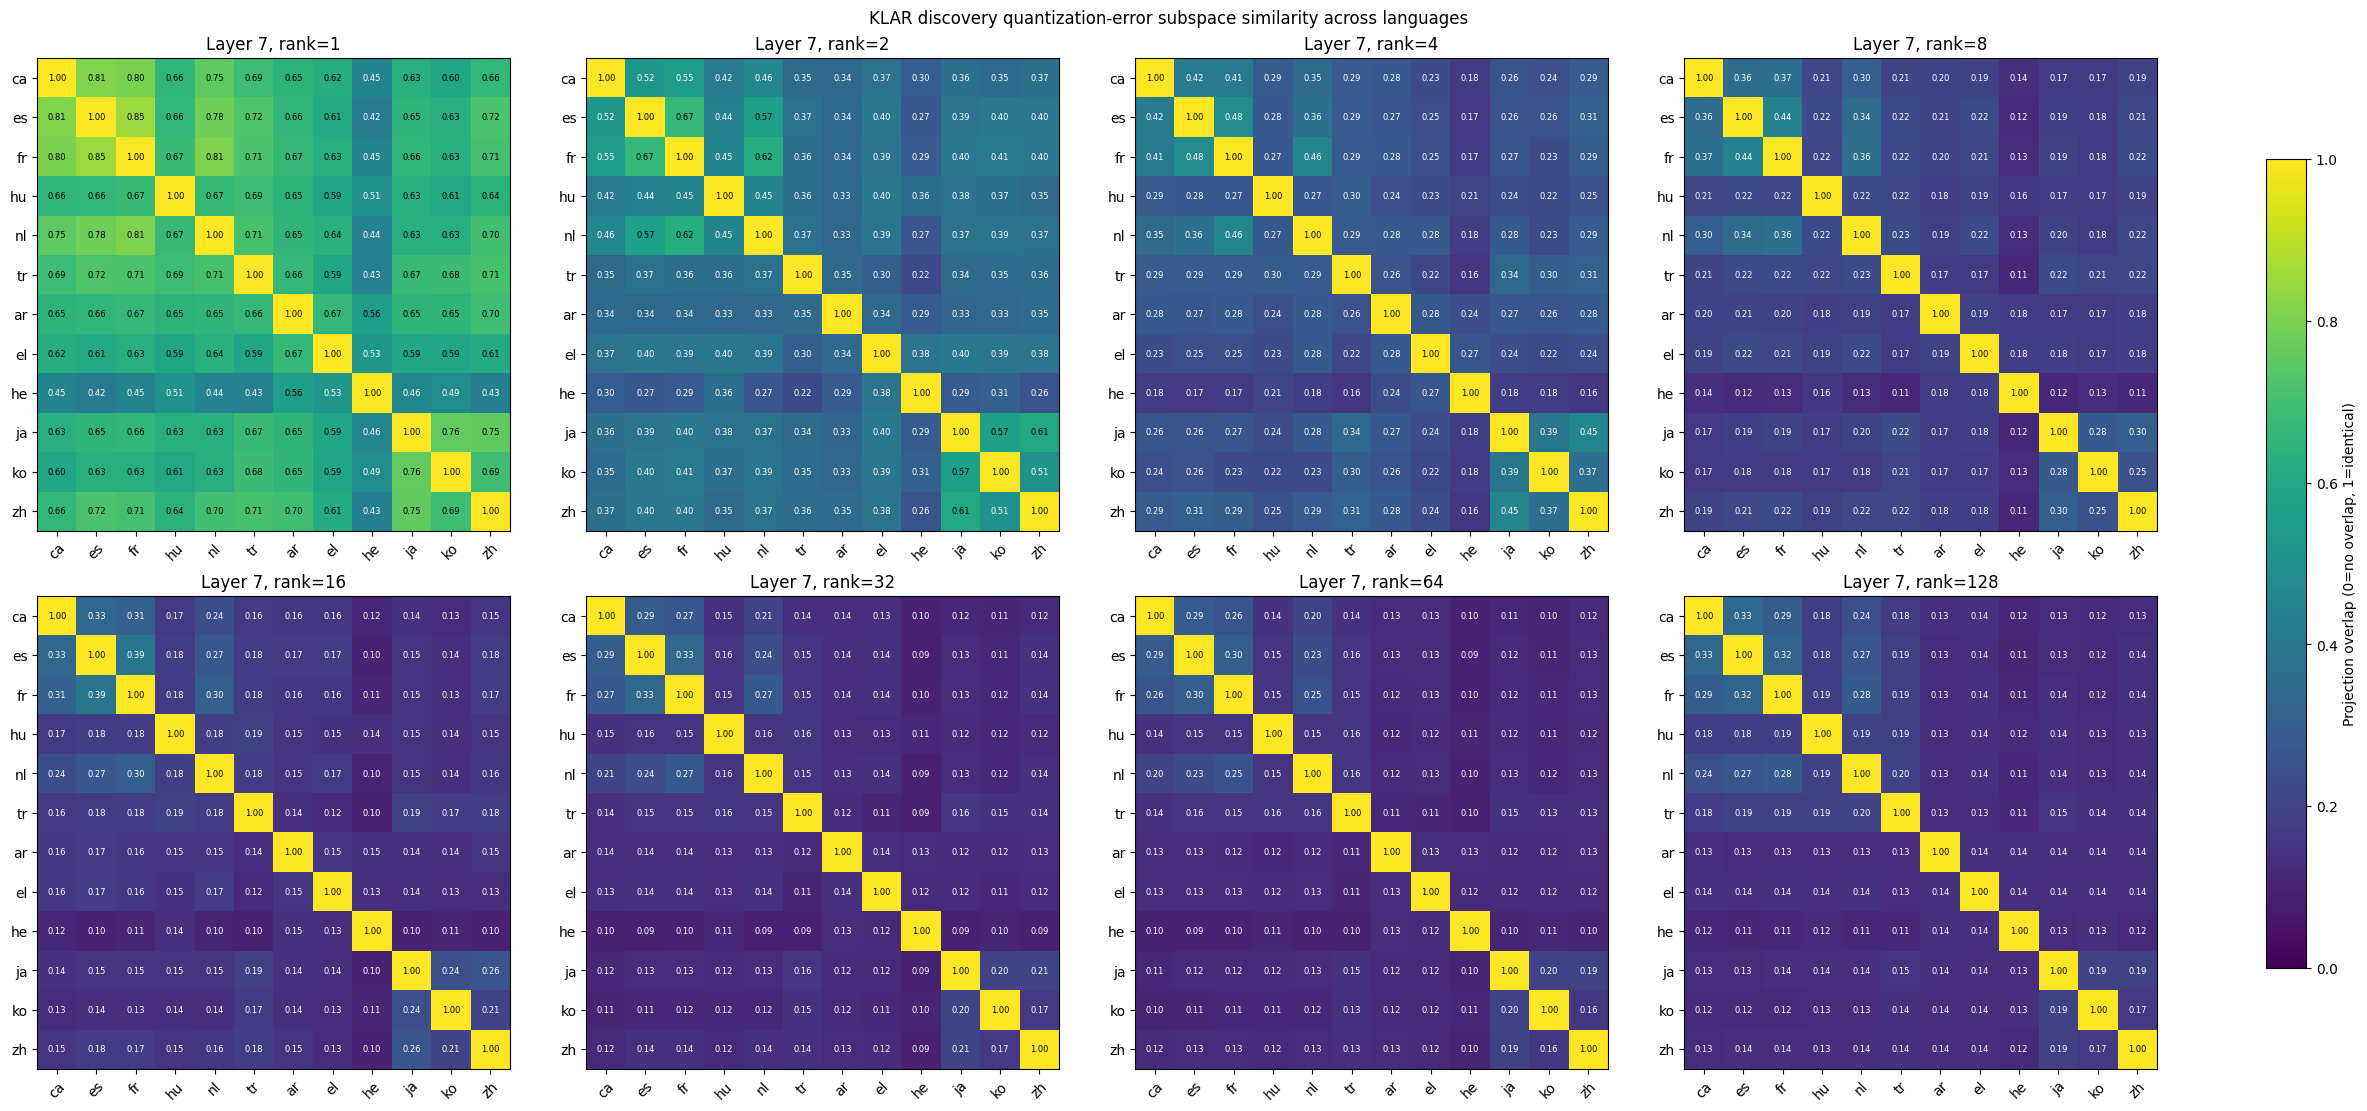

In [6]:
def projection_overlap(basis_a, basis_b):
    basis_a = basis_a.float()
    basis_b = basis_b.float()
    denominator = max(1, min(basis_a.shape[1], basis_b.shape[1]))
    overlap = (basis_a.T @ basis_b).square().sum() / denominator
    return float(overlap.clamp(0.0, 1.0))


similarity_rows = []
affinity_rows = []
for rank in SUBSPACE_DIMS:
    for language_a in TARGET_LANGUAGES:
        basis_a = LANGUAGE_BASES_MAX[language_a][:, :rank]
        for language_b in TARGET_LANGUAGES:
            basis_b = LANGUAGE_BASES_MAX[language_b][:, :rank]
            similarity_rows.append({
                'rank': rank,
                'language_a': language_a,
                'language_b': language_b,
                'same_script_group': (
                    LANGUAGE_SCRIPT_GROUPS[language_a]
                    == LANGUAGE_SCRIPT_GROUPS[language_b]
                ),
                'projection_overlap': projection_overlap(basis_a, basis_b),
            })

        group = LANGUAGE_SCRIPT_GROUPS[language_a]
        affinity_rows.append({
            'rank': rank,
            'language': language_a,
            'script_group': group,
            'global_overlap': projection_overlap(
                basis_a, GLOBAL_BASES[rank]
            ),
            'own_group_overlap': projection_overlap(
                basis_a, GROUP_BASES[group][rank]
            ),
        })

KLAR_DISCOVERY_SUBSPACE_SIMILARITY_DF = pd.DataFrame(similarity_rows)
KLAR_DISCOVERY_SUBSPACE_AFFINITY_DF = pd.DataFrame(affinity_rows)
KLAR_DISCOVERY_SUBSPACE_SIMILARITY_DF.to_csv(
    OUTPUT_DIR / 'klar_discovery_language_subspace_similarity.csv', index=False
)
KLAR_DISCOVERY_SUBSPACE_AFFINITY_DF.to_csv(
    OUTPUT_DIR / 'klar_discovery_language_common_basis_affinity.csv', index=False
)

pair_summary_rows = []
for rank in SUBSPACE_DIMS:
    part = KLAR_DISCOVERY_SUBSPACE_SIMILARITY_DF[
        KLAR_DISCOVERY_SUBSPACE_SIMILARITY_DF['rank'] == rank
    ].copy()
    part = part[part.language_a < part.language_b]
    for pair_type, mask in {
        'within_script_group': part.same_script_group,
        'cross_script_group': ~part.same_script_group,
    }.items():
        values = part.loc[mask, 'projection_overlap']
        pair_summary_rows.append({
            'rank': rank,
            'pair_type': pair_type,
            'pairs': len(values),
            'mean_overlap': values.mean(),
            'std_overlap': values.std(),
        })
KLAR_DISCOVERY_SUBSPACE_PAIR_SUMMARY_DF = pd.DataFrame(pair_summary_rows)
KLAR_DISCOVERY_SUBSPACE_PAIR_SUMMARY_DF.to_csv(
    OUTPUT_DIR / 'klar_discovery_subspace_pair_summary.csv', index=False
)

display(KLAR_DISCOVERY_SUBSPACE_PAIR_SUMMARY_DF)
display(KLAR_DISCOVERY_SUBSPACE_AFFINITY_DF)

similarity_ncols = min(4, len(SUBSPACE_DIMS))
similarity_nrows = math.ceil(len(SUBSPACE_DIMS) / similarity_ncols)
fig, axes = plt.subplots(
    similarity_nrows, similarity_ncols,
    figsize=(6 * similarity_ncols, 5.5 * similarity_nrows),
    constrained_layout=True,
    squeeze=False,
)
last_image = None
for axis, rank in zip(axes.ravel(), SUBSPACE_DIMS):
    matrix = (
        KLAR_DISCOVERY_SUBSPACE_SIMILARITY_DF[
            KLAR_DISCOVERY_SUBSPACE_SIMILARITY_DF['rank'] == rank
        ]
        .pivot(index='language_a', columns='language_b', values='projection_overlap')
        .reindex(index=TARGET_LANGUAGES, columns=TARGET_LANGUAGES)
    )
    last_image = axis.imshow(
        matrix.to_numpy(), vmin=0, vmax=1, cmap='viridis', aspect='equal'
    )
    axis.set_title(f'Layer {RECOVERY_LAYER}, rank={rank}')
    axis.set_xticks(range(len(TARGET_LANGUAGES)), TARGET_LANGUAGES, rotation=45)
    axis.set_yticks(range(len(TARGET_LANGUAGES)), TARGET_LANGUAGES)
    for row_index in range(len(TARGET_LANGUAGES)):
        for column_index in range(len(TARGET_LANGUAGES)):
            value = matrix.iloc[row_index, column_index]
            axis.text(
                column_index, row_index, f'{value:.2f}',
                ha='center', va='center', fontsize=6,
                color='white' if value < 0.55 else 'black',
            )
for axis in axes.ravel()[len(SUBSPACE_DIMS):]:
    axis.axis('off')
fig.colorbar(last_image, ax=axes.ravel().tolist(), shrink=.8,
             label='Projection overlap (0=no overlap, 1=identical)')
fig.suptitle('KLAR discovery quantization-error subspace similarity across languages')
plt.show()


## 4. Freeze the held-out KLAR evaluation subset

Only rows marked `evaluation` are passed to the recovery stage. The discovery facts are excluded by construction. Baseline outputs are regenerated in the same run as the intervention conditions.


In [7]:
KLAR_EVAL_DF = KLAR_SPLIT_DF[
    KLAR_SPLIT_DF.split == 'evaluation'
].copy()
if KLAR_EVAL_DF.empty:
    raise RuntimeError('Held-out KLAR evaluation subset is empty.')
if KLAR_EVAL_DF.sample_id.duplicated().any():
    raise RuntimeError('Duplicate held-out sample IDs.')

KLAR_EVAL_DF.to_csv(
    OUTPUT_DIR / 'klar_heldout_evaluation_pool.csv', index=False
)
display(KLAR_EVAL_DF.groupby(
    ['script_group', 'language'], as_index=False
).agg(
    samples=('sample_id', 'size'),
    relations=('relation_id', 'nunique'),
))
print('Held-out evaluation prompts:', len(KLAR_EVAL_DF))


,script_group,language,samples,relations
0,Latin,ca,20,15
1,Latin,es,20,15
2,Latin,fr,20,15
3,Latin,hu,20,15
4,Latin,nl,20,15
5,Latin,tr,20,15
6,Non-Latin,ar,20,15
7,Non-Latin,el,20,15
8,Non-Latin,he,20,15
9,Non-Latin,ja,20,15


Held-out evaluation prompts: 240


## 5. Held-out prompt encoding and exact-answer evaluation

In [8]:
def encode_klar_prompt_batch(rows):
    sequences = []
    for row in rows:
        prompt = klar_prompt_text(
            row['language'], int(row['record_id']), int(row['template_id'])
        )
        ids = TOKENIZER(prompt, add_special_tokens=False)['input_ids']
        if len(ids) + KLAR_GENERATION_MAX_NEW_TOKENS > KLAR_MAX_LENGTH:
            raise ValueError(
                f'{row["sample_id"]}: prompt exceeds KLAR_MAX_LENGTH.'
            )
        sequences.append(ids)
    width = max(map(len, sequences))
    pad_id = int(TOKENIZER.pad_token_id)
    input_ids = torch.full((len(rows), width), pad_id, dtype=torch.long)
    attention_mask = torch.zeros((len(rows), width), dtype=torch.long)
    for index, ids in enumerate(sequences):
        input_ids[index, width - len(ids):] = torch.tensor(ids, dtype=torch.long)
        attention_mask[index, width - len(ids):] = 1
    return {'input_ids': input_ids, 'attention_mask': attention_mask}


def normalize_generated_answer(text):
    import unicodedata
    normalized = unicodedata.normalize('NFKC', str(text))
    normalized = ' '.join(normalized.strip().split()).casefold()
    return normalized.strip(' \\t\\n\\r.,;:!?。；：！？"\'`“”‘’()[]{}')


def answer_correct(text, gold_answer):
    return normalize_generated_answer(text) == normalize_generated_answer(gold_answer)


def decode_new_tokens(rows):
    texts = []
    eos_id = TOKENIZER.eos_token_id
    pad_id = TOKENIZER.pad_token_id
    for token_ids in rows:
        kept = []
        for token_id in token_ids:
            token_id = int(token_id)
            if eos_id is not None and token_id == int(eos_id):
                break
            if pad_id is not None and token_id == int(pad_id):
                continue
            kept.append(token_id)
        texts.append(TOKENIZER.decode(kept, skip_special_tokens=True))
    return texts


## 6. Rank-1 projected versus direct intervention at Layer 7

Two rank-1 interventions use directions learned exclusively from discovery facts. The oracle projected condition is:

\[
h^{patched}=h^Q+\beta v_1v_1^\top(h^{FP}-h^Q).
\]

The fixed direct condition does not project the held-out error. It adds the discovery-derived principal RMS correction:

\[
h^{patched}=h^Q+\beta s_1\widetilde v_1,\qquad
s_1=\sqrt{\mathbb E_{discovery}(e^\top v_1)^2}.
\]

Both are evaluated at strength multipliers \(\beta\in\{1.0,1.5\}\). The held-out FP16 state is used only by the projected oracle and full-layer upper bound; the direct condition is fixed before evaluation.


In [9]:
CONDITION_SPECS = []
for rank in RECOVERY_RANKS:
    for beta in PATCH_BETAS:
        suffix = f'k{rank}_b{str(beta).replace(".", "p")}'
        base_kinds = [
            'global_unweighted', 'group_unweighted', 'language_unweighted',
            'global_energy', 'group_energy', 'random',
        ]
        CONDITION_SPECS.extend([
            {
                'name': f'{kind}_project_{suffix}', 'kind': kind,
                'mode': 'project', 'rank': rank, 'beta': beta,
            }
            for kind in base_kinds
        ])
CONDITION_SPECS.append({
    'name': 'full_layer7', 'kind': 'full', 'mode': 'full',
    'rank': None, 'beta': 1.0,
})
for rank in RECOVERY_RANKS:
    for beta in PATCH_BETAS:
        suffix = f'k{rank}_b{str(beta).replace(".", "p")}'
        CONDITION_SPECS.extend([
            {
                'name': f'{kind}_direct_rms_{suffix}', 'kind': kind,
                'mode': 'direct_rms', 'rank': rank, 'beta': beta,
            }
            for kind in [
                'global_unweighted', 'group_unweighted', 'language_unweighted',
                'global_energy', 'group_energy', 'random',
            ]
        ])
GENERATION_SPECS = [
    {
        'name': 'quant_baseline', 'kind': 'baseline', 'mode': 'baseline',
        'rank': None, 'beta': 0.0,
    }
] + CONDITION_SPECS


def basis_and_weights_for_condition(spec, language):
    rank = spec['rank']
    group = LANGUAGE_SCRIPT_GROUPS[language]
    if spec['kind'] == 'global_unweighted':
        return GLOBAL_BASES[rank], torch.ones(rank)
    if spec['kind'] == 'group_unweighted':
        return GROUP_BASES[group][rank], torch.ones(rank)
    if spec['kind'] == 'language_unweighted':
        return LANGUAGE_BASES_MAX[language][:, :rank], torch.ones(rank)
    if spec['kind'] == 'global_energy':
        return (
            WEIGHTED_GLOBAL_BASES[rank],
            WEIGHTED_GLOBAL_DIRECTION_WEIGHTS[rank],
        )
    if spec['kind'] == 'group_energy':
        return (
            WEIGHTED_GROUP_BASES[group][rank],
            WEIGHTED_GROUP_DIRECTION_WEIGHTS[group][rank],
        )
    if spec['kind'] == 'language_energy':
        return (
            LANGUAGE_BASES_MAX[language][:, :rank],
            LANGUAGE_ENERGY_WEIGHTS[language][rank],
        )
    if spec['kind'] == 'random':
        return RANDOM_BASES[rank], torch.ones(rank)
    if spec['kind'] in ('baseline', 'full'):
        return None, None
    raise KeyError(spec['kind'])


def discovery_errors_for_condition(spec, language):
    kind = spec['kind']
    if kind.startswith('global_'):
        return torch.cat([
            DISCOVERY_ERRORS[item].float() for item in TARGET_LANGUAGES
        ], dim=0)
    if kind.startswith('group_'):
        group = LANGUAGE_SCRIPT_GROUPS[language]
        return torch.cat([
            DISCOVERY_ERRORS[item].float()
            for item in TARGET_LANGUAGES
            if LANGUAGE_SCRIPT_GROUPS[item] == group
        ], dim=0)
    # Language and random controls use the same language-specific discovery rows.
    return DISCOVERY_ERRORS[language].float()


def build_direct_rms_correction(spec, language):
    if spec['rank'] != 1:
        raise ValueError('direct_rms is currently defined for rank 1 only.')
    basis, direction_weights = basis_and_weights_for_condition(spec, language)
    direction = basis[:, 0].float()
    coefficients = discovery_errors_for_condition(spec, language) @ direction
    rms_strength = coefficients.square().mean().sqrt()
    orientation = torch.where(
        coefficients.mean() < 0,
        torch.tensor(-1.0), torch.tensor(1.0),
    )
    strength = rms_strength * direction_weights[0].float()
    return (orientation * strength * direction).contiguous()


DIRECT_RMS_CORRECTIONS = {
    (spec['name'], language): build_direct_rms_correction(spec, language)
    for spec in CONDITION_SPECS if spec['mode'] == 'direct_rms'
    for language in TARGET_LANGUAGES
}

DIRECT_RMS_SUMMARY_DF = pd.DataFrame([
    {
        'condition': spec['name'],
        'language': language,
        'script_group': LANGUAGE_SCRIPT_GROUPS[language],
        'correction_norm': float(
            DIRECT_RMS_CORRECTIONS[(spec['name'], language)].norm()
        ),
    }
    for spec in CONDITION_SPECS if spec['mode'] == 'direct_rms'
    for language in TARGET_LANGUAGES
])
DIRECT_RMS_SUMMARY_DF.to_csv(
    OUTPUT_DIR / 'direct_rms_correction_strengths.csv', index=False
)
display(DIRECT_RMS_SUMMARY_DF)


def hidden_from_layer_output(output):
    return output[0] if isinstance(output, tuple) else output


def replace_layer_hidden(output, hidden):
    if isinstance(output, tuple):
        return (hidden,) + output[1:]
    return hidden


@torch.no_grad()
def capture_fp_layer_output(
    fp_model, input_ids, attention_mask, past_key_values=None
):
    layer = decoder_layers(fp_model)[RECOVERY_LAYER]
    captured = {}

    def hook(_module, _inputs, output):
        captured['hidden'] = hidden_from_layer_output(output).detach()

    handle = layer.register_forward_hook(hook)
    try:
        result = fp_model(
            input_ids=input_ids.to(input_device(fp_model)),
            attention_mask=attention_mask.to(input_device(fp_model)),
            past_key_values=past_key_values,
            use_cache=USE_KV_CACHE, return_dict=True,
        )
    finally:
        handle.remove()
    return captured['hidden'], result.past_key_values


@torch.no_grad()
def patched_next_ids(
    q_model, input_ids, attention_mask, fp_hidden,
    condition_specs, language, base_batch_size, past_key_values=None,
):
    layer = decoder_layers(q_model)[RECOVERY_LAYER]

    def hook(_module, _inputs, output):
        q_hidden = hidden_from_layer_output(output)
        patched = q_hidden.clone()
        for condition_index, spec in enumerate(condition_specs):
            start = condition_index * base_batch_size
            stop = start + base_batch_size
            q_part = q_hidden[start:stop]
            if spec['kind'] == 'baseline':
                correction = torch.zeros_like(q_part, dtype=torch.float32)
            elif spec['mode'] == 'direct_rms':
                direct_vector = DIRECT_RMS_CORRECTIONS[
                    (spec['name'], language)
                ].to(device=q_part.device, dtype=torch.float32)
                correction = direct_vector.view(1, 1, -1).expand_as(q_part)
            else:
                fp_part = fp_hidden[start:stop].to(
                    device=q_part.device, dtype=q_part.dtype
                )
                error = fp_part.float() - q_part.float()
                if spec['kind'] == 'full':
                    correction = error
                else:
                    basis, direction_weights = basis_and_weights_for_condition(
                        spec, language
                    )
                    basis = basis.to(
                        device=q_part.device, dtype=torch.float32
                    )
                    direction_weights = direction_weights.to(
                        device=q_part.device, dtype=torch.float32
                    )
                    coefficients = torch.matmul(error, basis)
                    correction = torch.matmul(
                        coefficients * direction_weights, basis.T
                    )
            patched[start:stop] = (
                q_part.float() + float(spec['beta']) * correction
            ).to(q_part.dtype)
        return replace_layer_hidden(output, patched)

    handle = layer.register_forward_hook(hook)
    try:
        result = q_model(
            input_ids=input_ids.to(input_device(q_model)),
            attention_mask=attention_mask.to(input_device(q_model)),
            past_key_values=past_key_values,
            use_cache=USE_KV_CACHE, return_dict=True,
        )
        next_ids = result.logits[:, -1, :].float().argmax(dim=-1).cpu()
        return next_ids, result.past_key_values
    finally:
        handle.remove()


@torch.no_grad()
def generate_condition_chunk(fp_model, q_model, prompt_batch, specs, language):
    base_batch_size = prompt_batch['input_ids'].shape[0]
    condition_count = len(specs)
    step_input_ids = prompt_batch['input_ids'].repeat(condition_count, 1).cpu()
    mask = prompt_batch['attention_mask'].repeat(condition_count, 1).cpu()
    generated = [[] for _ in range(step_input_ids.shape[0])]
    finished = torch.zeros(step_input_ids.shape[0], dtype=torch.bool)
    eos_id = TOKENIZER.eos_token_id
    pad_id = int(TOKENIZER.pad_token_id)
    fp_past_key_values = None
    q_past_key_values = None

    for _ in range(KLAR_GENERATION_MAX_NEW_TOKENS):
        needs_fp = any(
            spec['mode'] in ('project', 'full') for spec in specs
        )
        if needs_fp:
            fp_hidden, fp_past_key_values = capture_fp_layer_output(
                fp_model, step_input_ids, mask, fp_past_key_values
            )
        else:
            fp_hidden = None
        next_ids, q_past_key_values = patched_next_ids(
            q_model, step_input_ids, mask, fp_hidden,
            specs, language, base_batch_size, q_past_key_values,
        )
        for row_index, token_id in enumerate(next_ids.tolist()):
            if not finished[row_index]:
                generated[row_index].append(token_id)
        was_finished = finished.clone()
        if eos_id is not None:
            finished |= next_ids.eq(int(eos_id))
        append_ids = torch.where(
            was_finished, torch.full_like(next_ids, pad_id), next_ids
        )
        step_input_ids = append_ids[:, None]
        mask = torch.cat([mask, (~was_finished).long()[:, None]], dim=1)
        del fp_hidden
        if bool(finished.all()):
            break

    del fp_past_key_values, q_past_key_values

    decoded = decode_new_tokens(generated)
    return {
        spec['name']: decoded[
            index * base_batch_size:(index + 1) * base_batch_size
        ]
        for index, spec in enumerate(specs)
    }


print('Generation conditions:', [spec['name'] for spec in GENERATION_SPECS])


,condition,language,script_group,correction_norm
0,global_unweighted_direct_rms_k1_b1p0,ca,Latin,0.345670
1,global_unweighted_direct_rms_k1_b1p0,es,Latin,0.345670
2,global_unweighted_direct_rms_k1_b1p0,fr,Latin,0.345670
3,global_unweighted_direct_rms_k1_b1p0,hu,Latin,0.345670
4,global_unweighted_direct_rms_k1_b1p0,nl,Latin,0.345670
...,...,...,...,...
139,random_direct_rms_k1_b1p5,el,Non-Latin,0.002930
140,random_direct_rms_k1_b1p5,he,Non-Latin,0.006990
141,random_direct_rms_k1_b1p5,ja,Non-Latin,0.008160
142,random_direct_rms_k1_b1p5,ko,Non-Latin,0.007590


Generation conditions: ['quant_baseline', 'global_unweighted_project_k1_b1p0', 'group_unweighted_project_k1_b1p0', 'language_unweighted_project_k1_b1p0', 'global_energy_project_k1_b1p0', 'group_energy_project_k1_b1p0', 'random_project_k1_b1p0', 'global_unweighted_project_k1_b1p5', 'group_unweighted_project_k1_b1p5', 'language_unweighted_project_k1_b1p5', 'global_energy_project_k1_b1p5', 'group_energy_project_k1_b1p5', 'random_project_k1_b1p5', 'full_layer7', 'global_unweighted_direct_rms_k1_b1p0', 'group_unweighted_direct_rms_k1_b1p0', 'language_unweighted_direct_rms_k1_b1p0', 'global_energy_direct_rms_k1_b1p0', 'group_energy_direct_rms_k1_b1p0', 'random_direct_rms_k1_b1p0', 'global_unweighted_direct_rms_k1_b1p5', 'group_unweighted_direct_rms_k1_b1p5', 'language_unweighted_direct_rms_k1_b1p5', 'global_energy_direct_rms_k1_b1p5', 'group_energy_direct_rms_k1_b1p5', 'random_direct_rms_k1_b1p5']


## 7. Run recovery on held-out KLAR facts

The quantized model is loaded before FP16. KV caching avoids recomputing the full prompt after the first generated token, and results are saved incrementally at the end of the run.


In [10]:
RESULT_PATH = OUTPUT_DIR / (
    f'klar_{QUANT_MODEL_NAME.lower().replace("-", "_")}_'
    f'layer{RECOVERY_LAYER}_subspace_recovery.csv'
)

if RESULT_PATH.exists() and not RECOMPUTE_KLAR_RECOVERY:
    KLAR_RECOVERY_DF = pd.read_csv(RESULT_PATH)
    print('Loaded:', RESULT_PATH)
else:
    q_model = load_model(QUANT_MODEL_NAME)
    fp_model = load_model('FP16')
    output_rows = []

    for language in TARGET_LANGUAGES:
        language_df = KLAR_EVAL_DF[
            KLAR_EVAL_DF.language == language
        ].sort_values('language_sample_index')
        language_rows = language_df.to_dict('records')
        if not language_rows:
            continue

        for start in tqdm(
            range(0, len(language_rows), KLAR_BATCH_SIZE),
            desc=f'KLAR subspace:{language}',
        ):
            rows = language_rows[start:start + KLAR_BATCH_SIZE]
            prompt_batch = encode_klar_prompt_batch(rows)
            condition_outputs = {}
            for condition_start in range(
                0, len(GENERATION_SPECS), PATCH_CONDITIONS_PER_BATCH
            ):
                condition_chunk = GENERATION_SPECS[
                    condition_start:condition_start + PATCH_CONDITIONS_PER_BATCH
                ]
                condition_outputs.update(generate_condition_chunk(
                    fp_model, q_model, prompt_batch,
                    condition_chunk, language,
                ))

            for row_index, row in enumerate(rows):
                baseline_text = condition_outputs['quant_baseline'][row_index]
                result = {
                    'model': QUANT_MODEL_NAME,
                    'language': language,
                    'script_group': LANGUAGE_SCRIPT_GROUPS[language],
                    'sample_id': row['sample_id'],
                    'gold_answer': row['answer'],
                    'quant_baseline_output_text': baseline_text,
                    'quant_baseline_correct': answer_correct(
                        baseline_text, row['answer']
                    ),
                }
                for spec in CONDITION_SPECS:
                    text = condition_outputs[spec['name']][row_index]
                    result[f'{spec["name"]}_output_text'] = text
                    result[f'{spec["name"]}_correct'] = answer_correct(
                        text, row['answer']
                    )
                output_rows.append(result)
            del prompt_batch, condition_outputs

    KLAR_RECOVERY_DF = pd.DataFrame(output_rows)
    KLAR_RECOVERY_DF.to_csv(RESULT_PATH, index=False)
    del q_model, fp_model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    print('Saved:', RESULT_PATH)

display(KLAR_RECOVERY_DF.head())


Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

`torch_dtype` is deprecated! Use `dtype` instead!


BNB-NF4 placement: {'': 0}


Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

FP16 placement: {'': 0}


KLAR subspace:ca:   0%|          | 0/10 [00:00<?, ?it/s]

... (9 outputs left out)

KLAR subspace:ko:   0%|          | 0/10 [00:00<?, ?it/s]

KLAR subspace:zh:   0%|          | 0/10 [00:00<?, ?it/s]

Saved: /root/autodl-tmp/analysis/type1_bridge_neuron_stats_paper_tatoeba_1000_12targets_latin_nonlatin/content_masked_mean_tokens/klar_split_error_subspace_recovery/klar_bnb_nf4_layer7_subspace_recovery.csv


,model,language,script_group,sample_id,gold_answer,quant_baseline_output_text,quant_baseline_correct,global_unweighted_project_k1_b1p0_output_text,global_unweighted_project_k1_b1p0_correct,group_unweighted_project_k1_b1p0_output_text,...,group_unweighted_direct_rms_k1_b1p5_output_text,group_unweighted_direct_rms_k1_b1p5_correct,language_unweighted_direct_rms_k1_b1p5_output_text,language_unweighted_direct_rms_k1_b1p5_correct,global_energy_direct_rms_k1_b1p5_output_text,global_energy_direct_rms_k1_b1p5_correct,group_energy_direct_rms_k1_b1p5_output_text,group_energy_direct_rms_k1_b1p5_correct,random_direct_rms_k1_b1p5_output_text,random_direct_rms_k1_b1p5_correct
0,BNB-NF4,ca,Latin,ca:1030:0,Microsoft,Microsoft,True,Microsoft,True,Microsoft,...,Microsoft,True,Microsoft,True,Microsoft,True,Microsoft,True,Microsoft,True
1,BNB-NF4,ca,Latin,ca:649:4,Espanya,Espanya,True,Espanya,True,Espanya,...,Espanya,True,Espanya,True,Espanya,True,Espanya,True,Espanya,True
2,BNB-NF4,ca,Latin,ca:712:4,Apple Inc,Apple,False,Apple,False,Apple,...,Apple,False,Apple,False,Apple,False,Apple,False,Apple,False
3,BNB-NF4,ca,Latin,ca:491:1,Oceania,Oceania,True,Oceania,True,Oceania,...,Oceania,True,Oceania,True,Oceania,True,Oceania,True,Oceania,True
4,BNB-NF4,ca,Latin,ca:743:2,economia,Sociologia,False,Sociologia,False,Sociologia,...,Sociologia,False,Sociologia,False,Sociologia,False,Sociologia,False,Sociologia,False


## 8. Held-out recovery, collateral damage, and net gain

The primary metric is wrong-to-correct recovery on facts never used to discover the direction. Correct-to-wrong regressions are retained as collateral damage, and net held-out accuracy gain is the main summary.


,script_group,condition,kind,mode,rank,beta,samples,baseline_accuracy,patched_accuracy,net_accuracy_gain,baseline_wrong_n,recovered_n,failure_recovery_rate,baseline_correct_n,damaged_n,collateral_damage_rate
3,All,global_energy_project_k1_b1p0,global_energy,project,1.0,1.0,240,0.437500,0.437500,0.000000,135,2,0.014815,105,2,0.019048
9,All,global_energy_project_k1_b1p5,global_energy,project,1.0,1.5,240,0.437500,0.433333,-0.004167,135,2,0.014815,105,3,0.028571
16,All,global_energy_direct_rms_k1_b1p0,global_energy,direct_rms,1.0,1.0,240,0.437500,0.437500,0.000000,135,2,0.014815,105,2,0.019048
22,All,global_energy_direct_rms_k1_b1p5,global_energy,direct_rms,1.0,1.5,240,0.437500,0.437500,0.000000,135,2,0.014815,105,2,0.019048
0,All,global_unweighted_project_k1_b1p0,global_unweighted,project,1.0,1.0,240,0.437500,0.437500,0.000000,135,2,0.014815,105,2,0.019048
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
55,Non-Latin,random_project_k1_b1p0,random,project,1.0,1.0,120,0.383333,0.383333,0.000000,74,0,0.000000,46,0,0.000000
61,Non-Latin,random_project_k1_b1p5,random,project,1.0,1.5,120,0.383333,0.383333,0.000000,74,0,0.000000,46,0,0.000000
68,Non-Latin,random_direct_rms_k1_b1p0,random,direct_rms,1.0,1.0,120,0.383333,0.383333,0.000000,74,0,0.000000,46,0,0.000000
74,Non-Latin,random_direct_rms_k1_b1p5,random,direct_rms,1.0,1.5,120,0.383333,0.383333,0.000000,74,0,0.000000,46,0,0.000000


,language,script_group,condition,kind,mode,rank,beta,samples,baseline_accuracy,patched_accuracy,net_accuracy_gain,failure_recovery_rate,collateral_damage_rate
3,ar,Non-Latin,global_energy_project_k1_b1p0,global_energy,project,1.0,1.0,20,0.35,0.4,0.05,0.076923,0.0
9,ar,Non-Latin,global_energy_project_k1_b1p5,global_energy,project,1.0,1.5,20,0.35,0.4,0.05,0.076923,0.0
16,ar,Non-Latin,global_energy_direct_rms_k1_b1p0,global_energy,direct_rms,1.0,1.0,20,0.35,0.4,0.05,0.076923,0.0
22,ar,Non-Latin,global_energy_direct_rms_k1_b1p5,global_energy,direct_rms,1.0,1.5,20,0.35,0.4,0.05,0.076923,0.0
0,ar,Non-Latin,global_unweighted_project_k1_b1p0,global_unweighted,project,1.0,1.0,20,0.35,0.4,0.05,0.076923,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
280,zh,Non-Latin,random_project_k1_b1p0,random,project,1.0,1.0,20,0.60,0.6,0.00,0.000000,0.0
286,zh,Non-Latin,random_project_k1_b1p5,random,project,1.0,1.5,20,0.60,0.6,0.00,0.000000,0.0
293,zh,Non-Latin,random_direct_rms_k1_b1p0,random,direct_rms,1.0,1.0,20,0.60,0.6,0.00,0.000000,0.0
299,zh,Non-Latin,random_direct_rms_k1_b1p5,random,direct_rms,1.0,1.5,20,0.60,0.6,0.00,0.000000,0.0


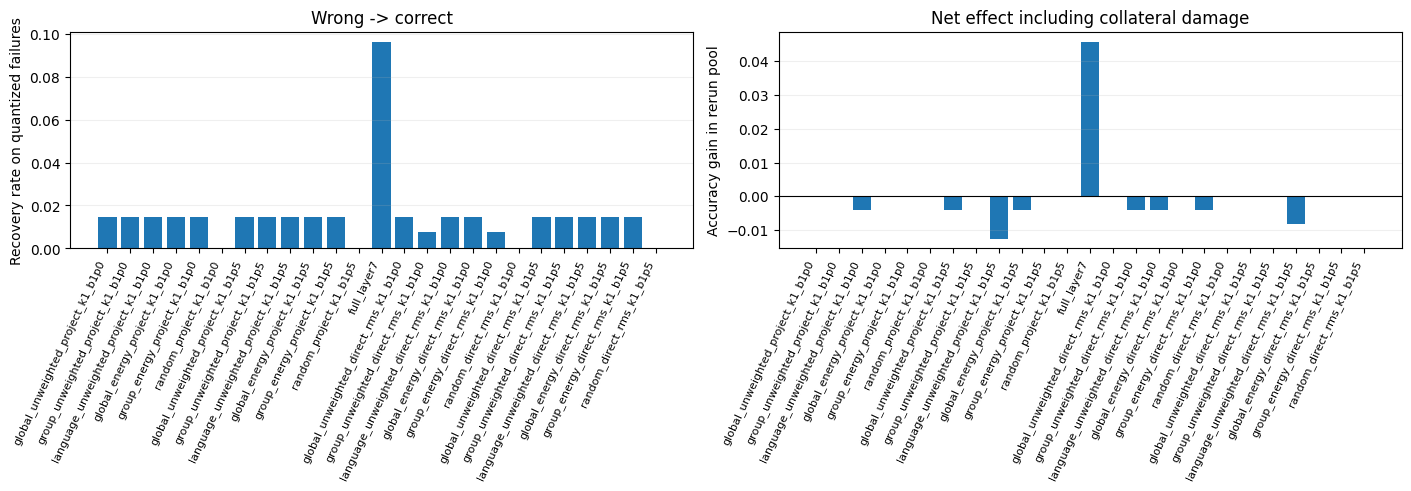

In [11]:
summary_rows = []
groupings = [('All', KLAR_RECOVERY_DF)] + [
    (group, KLAR_RECOVERY_DF[KLAR_RECOVERY_DF.script_group == group])
    for group in SCRIPT_GROUP_ORDER
]

for group_name, group_df in groupings:
    for spec in CONDITION_SPECS:
        patched = group_df[f'{spec["name"]}_correct'].astype(bool)
        baseline = group_df.quant_baseline_correct.astype(bool)
        wrong = ~baseline
        correct = baseline
        summary_rows.append({
            'script_group': group_name,
            'condition': spec['name'],
            'kind': spec['kind'],
            'mode': spec.get('mode'),
            'rank': spec['rank'],
            'beta': spec['beta'],
            'samples': len(group_df),
            'baseline_accuracy': baseline.mean(),
            'patched_accuracy': patched.mean(),
            'net_accuracy_gain': patched.mean() - baseline.mean(),
            'baseline_wrong_n': int(wrong.sum()),
            'recovered_n': int((wrong & patched).sum()),
            'failure_recovery_rate': (
                float(patched[wrong].mean()) if wrong.any() else np.nan
            ),
            'baseline_correct_n': int(correct.sum()),
            'damaged_n': int((correct & ~patched).sum()),
            'collateral_damage_rate': (
                float((~patched[correct]).mean()) if correct.any() else np.nan
            ),
        })

SUBSPACE_RECOVERY_SUMMARY_DF = pd.DataFrame(summary_rows)
SUBSPACE_RECOVERY_SUMMARY_DF.to_csv(
    OUTPUT_DIR / 'subspace_recovery_summary.csv', index=False
)

language_rows = []
for language, part in KLAR_RECOVERY_DF.groupby('language'):
    baseline = part.quant_baseline_correct.astype(bool)
    for spec in CONDITION_SPECS:
        patched = part[f'{spec["name"]}_correct'].astype(bool)
        language_rows.append({
            'language': language,
            'script_group': LANGUAGE_SCRIPT_GROUPS[language],
            'condition': spec['name'],
            'kind': spec['kind'],
            'mode': spec.get('mode'),
            'rank': spec['rank'],
            'beta': spec['beta'],
            'samples': len(part),
            'baseline_accuracy': baseline.mean(),
            'patched_accuracy': patched.mean(),
            'net_accuracy_gain': patched.mean() - baseline.mean(),
            'failure_recovery_rate': (
                float(patched[~baseline].mean()) if (~baseline).any() else np.nan
            ),
            'collateral_damage_rate': (
                float((~patched[baseline]).mean()) if baseline.any() else np.nan
            ),
        })

SUBSPACE_RECOVERY_BY_LANGUAGE_DF = pd.DataFrame(language_rows)
SUBSPACE_RECOVERY_BY_LANGUAGE_DF.to_csv(
    OUTPUT_DIR / 'subspace_recovery_by_language.csv', index=False
)

display(SUBSPACE_RECOVERY_SUMMARY_DF.sort_values([
    'script_group', 'rank', 'kind'
]))
display(SUBSPACE_RECOVERY_BY_LANGUAGE_DF.sort_values([
    'language', 'rank', 'kind'
]))

plot_df = SUBSPACE_RECOVERY_SUMMARY_DF[
    SUBSPACE_RECOVERY_SUMMARY_DF.script_group == 'All'
].copy()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), constrained_layout=True)
x = np.arange(len(plot_df))
axes[0].bar(x, plot_df.failure_recovery_rate)
axes[0].set_ylabel('Recovery rate on quantized failures')
axes[0].set_title('Wrong -> correct')
axes[1].bar(x, plot_df.net_accuracy_gain)
axes[1].axhline(0, color='black', lw=.8)
axes[1].set_ylabel('Accuracy gain in rerun pool')
axes[1].set_title('Net effect including collateral damage')
for ax in axes:
    ax.set_xticks(x, plot_df.condition, rotation=65, ha='right', fontsize=8)
    ax.grid(axis='y', alpha=.2)
plt.show()


## 9. Interpretation

This experiment is the minimum non-circular mechanism test. Rank-1 receives support only when a discovery-only direction improves held-out KLAR accuracy, beats rank-1 random, and has acceptable collateral damage. If same-dataset held-out recovery succeeds but Tatoeba-to-KLAR fails, the direction is in-domain but not cross-dataset stable. If both fail while full Layer-7 replacement succeeds, useful error is distributed across more than one direction. If full replacement also fails, Layer 7 alone is not a sufficient intervention boundary.
